<h1 align="center">Física Computacional.</h1>
<h1 align="center">Semestre 2027-1</h1>

<h2>Franco Olvera Ángel Jesús </h2> 

---


<h1 align="center">Programación para la física computacional</h1> 

## Práctica 5.  Métodos de diferenciación numérica

---

### **EJERCICIOS**:

$\;$

### **1.  Diferenciación numérica** 
Crea una funcion f(x) que devuelva $$ 1 + \frac{1}{2}tanh(2x)$$, luego usa diferencias centrales
para calcular numericamente la derivada de la funcion en el intervalo $ −2 ≤ x ≤ 2$.
Despues, calcula la derivada analíticamente y haz una grafica con tu resultado numérico
y la respuesta anal´ıtica en el mismo grafico
#### 

De forma analítica tenemos:
$$f'(x) = \frac{d}{dx}tanh(u) = sech^2(u)\frac{du}{dx}$$
$$f'(x) = \frac{1}{2}sech^2(2x)(2) = sech^2(2x) = \frac{1}{cosh^2(2x)}

In [1]:
import math as mt
import numpy as np
import matplotlib.pyplot as plt


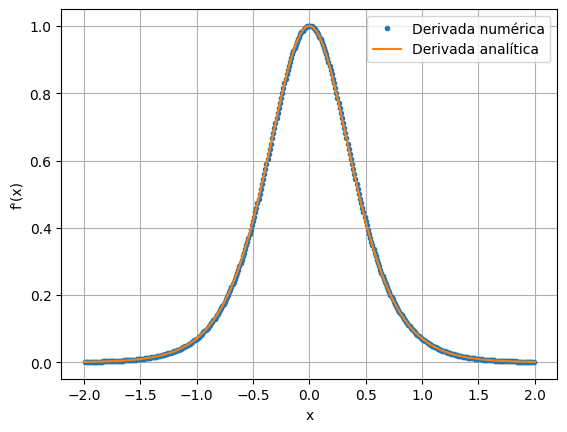

In [23]:
h=0.01 #Tomamos h pequeña

#Definimos la función f
def f(x):
    return 1 + (1/2)*mt.tanh(2*x)
#Tomamos el rango que queremos
x= np.arange(-2, 2+h, h)
#Arreglo vacío para ir guardando los valroes de la derivada numérica
derivadanum = []

#hacemos las diferencias centrales
for i in range(1,len(x)-1):
    derivada= (f(x[i]+h/2)-f(x[i]-h/2)) / h
    derivadanum.append(derivada)

xnum=x[1:-1]

#Valor de la derivada analítica
derivadanalit = 1 / np.cosh(2*x)**2

#Hacemos la gráfica
plt.plot(xnum, derivadanum , ".", label = "Derivada numérica")
plt.plot(x, derivadanalit, label = "Derivada analítica")

plt.xlabel("x")
plt.ylabel("f'(x)")
plt.grid()
plt.legend()

### **2.  Campo eléctrico de una distribución de cargas** 
(a) Suponiendo que tienes dos cargas, de +1 C y −1 C (respectivamente), separadas
10 cm. Calcula el potencial electrico resultante en un plano cuadrado de 1 m  ×
1 m que rodea las cargas y pasa a traves de ellas. Calcula el potencial en puntos 
espaciados a 1 cm en una cuadr´ıcula y haz una visualizacion en la pantalla del 
potencial usando un grafico de densidad
#### 

In [24]:
import numpy as np
import matplotlib.pyplot as plt

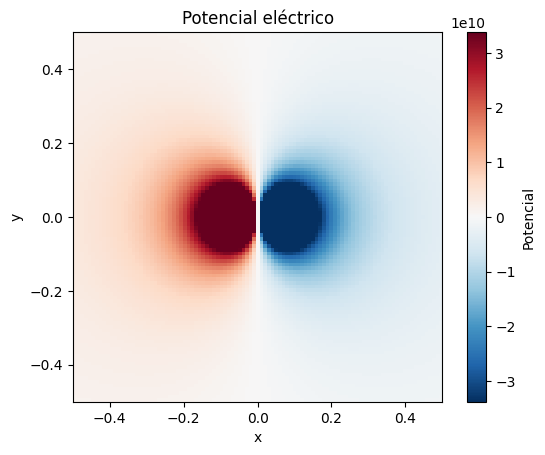

In [62]:
#constantes
e0= 8.854e-12
k = 1 /(4*np.pi*e0)
q1 = 1
q2= -1

#Creamos el plano
x = np.linspace(-0.5, 0.5, 101)
y = np.linspace(-0.5, 0.5, 101)

X,Y = np.meshgrid(x,y)

#separaciond e las cargas
r1 = np.sqrt((X+0.05)**2 + Y**2) #supongamos que la carga 1 está en (-0.05,0)
r2 = np.sqrt((X-0.05)**2 + Y**2) #supongamos que la carga 2 está en (+0.05,0), la separacion es de 10cm

#Calculamos el potencial
potencial = k * (q1/r1 +q2/r2)

#No tomamos en cuenta la distancia = 0
potencial[r1 == 0] = np.nan
potencial[r2 == 0] = np.nan

#Limitamos los colores para que se vean y no divergan
pot_lim = np.percentile(np.abs(potencial), 95)

#Graficamos
plt.imshow(potencial, extent=[-0.5, 0.5, -0.5, 0.5], cmap="RdBu_r",vmin=-pot_lim, vmax=pot_lim )
plt.title("Potencial eléctrico")
plt.xlabel('x')
plt.ylabel('y')

plt.colorbar(label="Potencial")
plt.show()

###
(b) Ahora calcula las derivadas parciales del potencial con respecto a x y y, para
encontrar el campo electrico en el plano xy y realiza una visualizacion de dicho
campo.
#### 

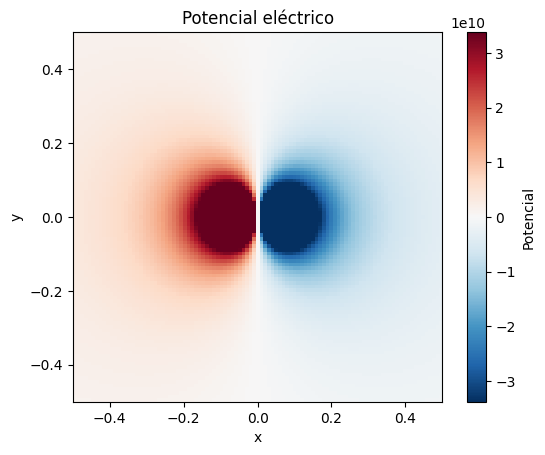

In [42]:
#constantes
e0= 8.854e-12
k = 1 /(4*np.pi*e0)
q1 = 1
q2= -1

#Creamos el plano
x = np.linspace(-0.5, 0.5, 101)
y = np.linspace(-0.5, 0.5, 101)

X,Y = np.meshgrid(x,y)

#separaciond e las cargas
r1 = np.sqrt((X+0.05)**2 + Y**2) #supongamos que la carga 1 está en (-0.05,0)
r2 = np.sqrt((X-0.05)**2 + Y**2) #supongamos que la carga 2 está en (+0.05,0), la separacion es de 10cm

#Calculamos el potencial
potencial = k * (q1/r1 +q2/r2)

#No tomamos en cuenta la distancia = 0
potencial[r1 == 0] = np.nan
potencial[r2 == 0] = np.nan

#Limitamos los colores para que se vean y no divergan
pot_lim = np.percentile(np.abs(potencial), 95)

#Graficamos
plt.imshow(potencial, extent=[-0.5, 0.5, -0.5, 0.5], cmap="RdBu_r",vmin=-pot_lim, vmax=pot_lim )
plt.title("Potencial eléctrico")
plt.xlabel('x')
plt.ylabel('y')

plt.colorbar(label="Potencial")
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt

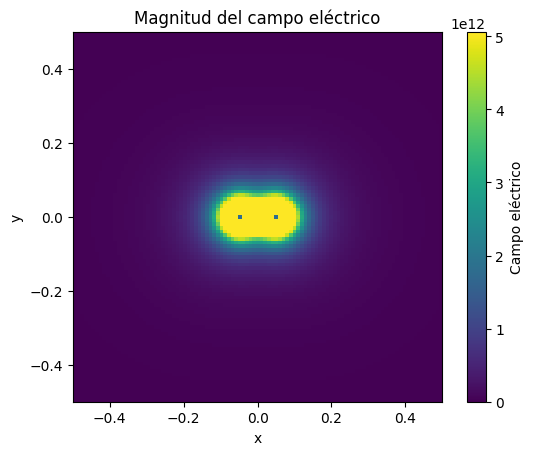

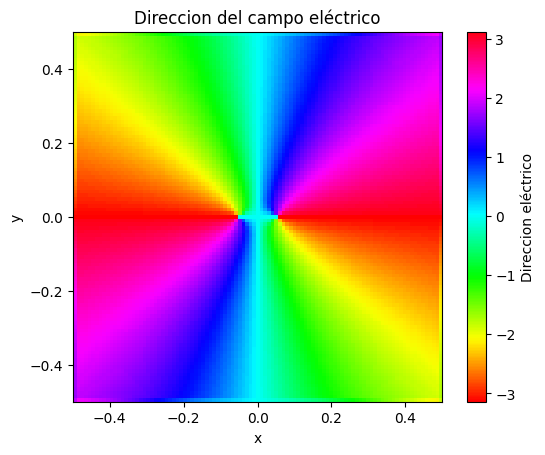

In [67]:
#dimensiones n y m
n,m = potencial.shape

#Creamos dos matrices vacíaas para guardas las derivadas, hice primero el 3 xd, así que copiamos y cambiamos cositas nada mas.

dV_dx = np.zeros((n,m))
dV_dy = np.zeros((n,m))

#Calculamos las derivadas respecto a x

for i in range(n):
    #parte central, usamos otro for
    for j in range(1,m-1):
        dV_dx[i,j]= (potencial[i,j+1]-potencial[i,j-1]) / h 

    #En los extremos tenemos: (con y=0 y usando diferencias hacia adelante)
    dV_dx[i,0] = (potencial[i,1]-potencial[i,0])/h

    dV_dx[i,m-1] = (potencial[i,m-1]-potencial[i,m-2])/h #Diferencias hacia atrás en el ultimo punto

#De forma análoga, calculamos las derivadas respecto a y

for j in range(m):
    #parte central, usamos otro for
    for i in range(1,n-1):
        dV_dy[i,j]= (potencial[i+1,j] - potencial[i-1,j]) / h

    #En los extremos tenemos: (con x=0 y usando diferencias hacia adelante)
    dV_dy[0,j] = (potencial[1,j]-potencial[0,j])/h

    dV_dy[n-1,j] = (potencial[n-1,j]-potencial[n-2,j])/h #Diferencias hacia atrás en el ultimo punto


#Ahora calculamos el campo por entradas:
Ex = -dV_dx
Ey = -dV_dy

#La magnitud es:
E = np.sqrt(Ex**2 + Ey**2)
E_lim = np.percentile(E, 98) #Ponemos un límite para que se visualice


#Graficamos, primero la magnitud
plt.imshow(E, extent=[-0.5, 0.5, -0.5, 0.5], cmap="viridis", vmin=0, vmax= E_lim)
plt.title("Magnitud del campo eléctrico")
plt.xlabel('x')
plt.ylabel('y')

plt.colorbar(label="Campo eléctrico")
plt.show()

#Ahora graficamos la direccion usando hsv
E_direccion = np.arctan2(Ey,Ex)

plt.imshow(E_direccion, extent=[-0.5, 0.5, -0.5, 0.5], cmap="hsv")
plt.title("Direccion del campo eléctrico")
plt.xlabel('x')
plt.ylabel('y')

plt.colorbar(label="Direccion eléctrico")
plt.show()


### **3.  Procesamiento de imágenes y STM** 
(a)Escribe un programa que lea este
archivo y almacene los datos en una matriz. Luego calcula las derivadas ∂w/∂x
y ∂w/∂y en cada punto de la cuadr´ıcula. Explica que metodo utilizaste para calcularlos y por que
#### 


In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [69]:
#Leemos los datos
w = np.loadtxt("altitudes.txt")
h = 30000

#las dimensiones de la matriz q querems:
n,m = w.shape

#Usamos dos matrices de ceros para ir guardando todo
dw_dx = np.zeros((n,m))
dw_dy = np.zeros((n,m))

#Calculamos las derivadas respecto a x

for i in range(n):
    #parte central, usamos otro for
    for j in range(1,m-1):
        dw_dx[i,j]= (w[i,j+1]-w[i,j-1]) / h 

    #En los extremos tenemos: (con y=0 y usando diferencias hacia adelante)
    dw_dx[i,0] = (w[i,1]-w[i,0])/h

    dw_dx[i,m-1] = (w[i,m-1]-w[i,m-2])/h #Diferencias hacia atrás en el ultimo punto

#De forma análoga, calculamos las derivadas respecto a y

for j in range(m):
    #parte central, usamos otro for
    for i in range(1,n-1):
        dw_dy[i,j]= (w[i+1,j] - w[i-1,j]) / h

    #En los extremos tenemos: (con x=0 y usando diferencias hacia adelante)
    dw_dy[0,j] = (w[1,j]-w[0,j])/h

    dw_dy[n-1,j] = (w[n-1,j]-w[n-2,j])/h #Diferencias hacia atrás en el ultimo punto


###  
(b)Ahora, usando tus valores para las derivadas, calcula la intensidad para cada
punto de la cuadrícula, con $\phi = 45$ y haz un grafico de densidad de los valores
resultantes en el que el brillo de cada punto depende de la correspondiente valor
de intensidad. 
#### 


In [70]:
import numpy as np
import matplotlib.pyplot as plt

<function matplotlib.pyplot.show(close=None, block=None)>

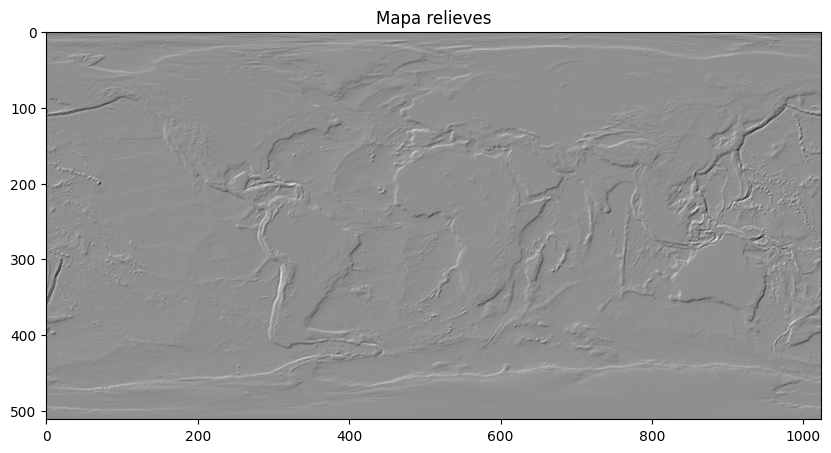

In [75]:
phi = np.radians(45) #Pasamos los grados a radianes

I=np.zeros((n,m)) #Matriz de ceros para ir guardando las intensidades

#Calculamos las intensidades
for i in range(n):
    for j in range(m):
        I [i,j]= (np.cos(phi)*dw_dx[i,j] + np.sin(phi)*dw_dy[i,j]) / np.sqrt((dw_dx[i,j]**2 + dw_dy[i,j]**2) +1)


plt.figure(figsize=(10,7))
plt.imshow(I, cmap = "gray")
plt.title("Mapa relieves")
plt.show

(c) Modifica tu programa anterior para
visualizar los datos STM y ası crear una imagen 3D de como se ve la superficie de 
silicio. El valor de h para las derivadas en este caso es de alrededor de h = 2.5 (en
unidades arbitrarias)




In [78]:
import numpy as np
import matplotlib.pyplot as plt

In [85]:
#Leemos los datos
w = np.loadtxt("stm.txt")
h = 2.5 #Básicamente sólo cambiamos estas dos líneas y yap:))

#las dimensiones de la matriz q querems:
n,m = w.shape

#Usamos dos matrices de ceros para ir guardando todo
dw_dx = np.zeros((n,m))
dw_dy = np.zeros((n,m))

#Calculamos las derivadas respecto a x

for i in range(n):
    #parte central, usamos otro for
    for j in range(1,m-1):
        dw_dx[i,j]= (w[i,j+1]-w[i,j-1]) / h 

    #En los extremos tenemos: (con y=0 y usando diferencias hacia adelante)
    dw_dx[i,0] = (w[i,1]-w[i,0])/h

    dw_dx[i,m-1] = (w[i,m-1]-w[i,m-2])/h #Diferencias hacia atrás en el ultimo punto

#De forma análoga, calculamos las derivadas respecto a y

for j in range(m):
    #parte central, usamos otro for
    for i in range(1,n-1):
        dw_dy[i,j]= (w[i+1,j] - w[i-1,j]) / h

    #En los extremos tenemos: (con x=0 y usando diferencias hacia adelante)
    dw_dy[0,j] = (w[1,j]-w[0,j])/h

    dw_dy[n-1,j] = (w[n-1,j]-w[n-2,j])/h #Diferencias hacia atrás en el ultimo punto

<function matplotlib.pyplot.show(close=None, block=None)>

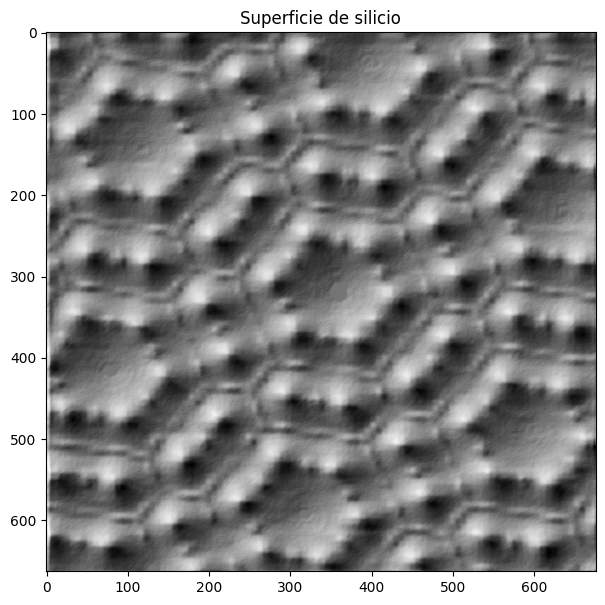

In [86]:
phi = np.radians(45) #Pasamos los grados a radianes

I=np.zeros((n,m)) #Matriz de ceros para ir guardando las intensidades

#Calculamos las intensidades
for i in range(n):
    for j in range(m):
        I [i,j]= (np.cos(phi)*dw_dx[i,j] + np.sin(phi)*dw_dy[i,j]) / np.sqrt((dw_dx[i,j]**2 + dw_dy[i,j]**2) +1)


plt.figure(figsize=(10,7))
plt.imshow(I, cmap = "gray")
plt.title("Superficie de silicio")
plt.show

### **4. Derivación mediante integración** 
Escribe un programa para calcular las primeras veinte derivadas de $f(z) = e^{
2z}$ en
z = 0 utilizando la ecuación 1 con N = 10000.

In [2]:
import numpy as np
import cmath as cmt
import math as mt

In [35]:
#Definimos zk, m y N
N=10000
m_maximo=20

k=np.arange(N) #Llega hasta N-1

z_k = np.exp(1j*2*np.pi*k/N)



#Definimos la función que queremos:
def f(z):
    return np.exp(2*z)

#evaluamos f en cada punto de z_k
f_z = f(z_k)

#Hacemos la suma y luego calculamos la derivada con la fórmula de cauchy
for m in range(1, m_maximo+1):
    suma = np.sum(f_z*np.exp(- 1j*2*mt.pi*k*m/N))

    derivada_z  = (mt.factorial(m)/N)  * suma


    print("Derivada núm. ", m, "| Derivada =", derivada_z.real, "| Resultado exacto teórico =", 2**m )

Derivada núm.  1 | Derivada = 2.0 | Resultado exacto teórico = 2
Derivada núm.  2 | Derivada = 4.0 | Resultado exacto teórico = 4
Derivada núm.  3 | Derivada = 8.0 | Resultado exacto teórico = 8
Derivada núm.  4 | Derivada = 16.0 | Resultado exacto teórico = 16
Derivada núm.  5 | Derivada = 32.0 | Resultado exacto teórico = 32
Derivada núm.  6 | Derivada = 64.00000000000003 | Resultado exacto teórico = 64
Derivada núm.  7 | Derivada = 128.0000000000001 | Resultado exacto teórico = 128
Derivada núm.  8 | Derivada = 256.0000000000017 | Resultado exacto teórico = 256
Derivada núm.  9 | Derivada = 512.000000000023 | Resultado exacto teórico = 512
Derivada núm.  10 | Derivada = 1024.0000000000812 | Resultado exacto teórico = 1024
Derivada núm.  11 | Derivada = 2048.0000000052983 | Resultado exacto teórico = 2048
Derivada núm.  12 | Derivada = 4096.000000050305 | Resultado exacto teórico = 4096
Derivada núm.  13 | Derivada = 8192.000000497459 | Resultado exacto teórico = 8192
Derivada núm.  